# Inference Lab: Pricing Under Uncertainty


**Run this notebook in Google Colab.** The `demand` module is compiled for Linux and Python 3.13 only, so it will not import on a Mac or Windows machine.

The goal of this lab is to use what you've learned in this class to find the optimal price for something. You can't know for sure what the underlying curve of revenue vs price looks like. All you know is what you would know in the real world, information you gain by sampling-- you can market test any price using the demand function below. When you set the price, the market test runs for a certain amount of time, and then reports responses-- a list of 1s (bought) and 0s (didn't buy) for that price point. The total number in the sample, $n$, is therefore a random variable, given by `len(responses)`. The number of consumers who buy the product is `responses.sum().` Every time you run a market test, it takes time (literally, it will take a while to run, so don't do this lab last minute!).

In [1]:
!git clone -q https://github.com/smgroves/demand_lab.git

%cd /content/demand_lab

from demand import demand

responses = demand(price=14.0)

print(len(responses), responses.sum())

/content/demand_lab
187 136


## 1. Compare two prices

Run one market test with price = 30. Then test price = 25. Which price earns more revenue per potential customer?

1. For each price, estimate the proportion $\hat{p}$ of customers who buy, and the revenue per customer $\hat{r}$.
2. Estimate the standard error of each $\hat{r}$ by bootstrapping.
3. Compute a 95% confidence interval for each $\hat{r}$.
4. Compute a 95% confidence interval for the difference $\hat{r}_{25} - \hat{r}_{30}$.
   
5. Interpret the estimates, SEs, and intervals. Report which price earns more profit, and how confident you are.



In [2]:
# part 1
price_A, price_B = 25, 30
resp_A = demand(price_A)
resp_B = demand(price_B)
for P, resp in [(price_A, resp_A), (price_B, resp_B)]:
    print(f"${P:g}: n = {len(resp)}, p_hat = {resp.mean():.3f}, r_hat = {P * resp.mean():.2f}")


$25: n = 161, p_hat = 0.410, r_hat = 10.25
$30: n = 173, p_hat = 0.335, r_hat = 10.06


In [3]:
# part 2
import numpy as np
import pandas as pd

B = 2000
seed = 123
rng = np.random.default_rng(seed)

def bootstrap_r(responses, price, B=B):
    """B bootstrap values of r_hat."""
    idx = rng.integers(0, len(responses), size=(B, len(responses)))
    return price * responses[idx].mean(axis=1)

def se_formula(responses, price):
    """SE of r_hat from P * sqrt(p_hat (1 - p_hat) / n)."""
    p = responses.mean()
    return price * np.sqrt(p * (1 - p) / len(responses))

reps_A = bootstrap_r(resp_A, price_A)
reps_B = bootstrap_r(resp_B, price_B)

pd.DataFrame([
    {"price": price_A, "r_hat": price_A * resp_A.mean(),
     "SE (bootstrap)": reps_A.std(ddof=1), "SE (formula)": se_formula(resp_A, price_A)},
    {"price": price_B, "r_hat": price_B * resp_B.mean(),
     "SE (bootstrap)": reps_B.std(ddof=1), "SE (formula)": se_formula(resp_B, price_B)},
]).round(3)

,price,r_hat,SE (bootstrap),SE (formula)
0,25,10.248,0.984,0.969
1,30,10.058,1.088,1.077


In [4]:
# part 3
def ci_table(pairs):
    rows = []
    for P, resp, reps in pairs:
        r_hat, se = P * resp.mean(), se_formula(resp, P)
        lo_b, hi_b = np.percentile(reps, [2.5, 97.5])
        rows.append({"price": P, "n": len(resp), "r_hat": round(r_hat, 2),
                     "95% CI (bootstrap)": f"({lo_b:.2f}, {hi_b:.2f})",
                     "95% CI (r_hat ± 1.96 SE)": f"({r_hat - 1.96 * se:.2f}, {r_hat + 1.96 * se:.2f})"})
    return pd.DataFrame(rows)

ci_table([(price_A, resp_A, reps_A), (price_B, resp_B, reps_B)])

,price,n,r_hat,95% CI (bootstrap),95% CI (r_hat ± 1.96 SE)
0,25,161,10.25,"(8.39, 12.12)","(8.35, 12.15)"
1,30,173,10.06,"(7.80, 12.14)","(7.95, 12.17)"


In [5]:
# part 4: 95% confidence interval for gap
def diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B):
    """95% CI for r_A - r_B, from the bootstrap and from the formula."""
    d = price_A * resp_A.mean() - price_B * resp_B.mean()
    boot = tuple(np.percentile(reps_A - reps_B, [2.5, 97.5]))
    se = np.sqrt(se_formula(resp_A, price_A) ** 2 + se_formula(resp_B, price_B) ** 2)
    return d, boot, (d - 1.96 * se, d + 1.96 * se)

def verdict(lo, hi, name_A, name_B):
    if lo > 0:
        return f"{name_A} earns more"
    if hi < 0:
        return f"{name_B} earns more"
    return "can't tell (interval contains 0)"

d, boot, z = diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B)
print(f"r_25 - r_30 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$25', '$30')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$25', '$30')}")


r_25 - r_30 = 0.19
  95% CI, bootstrap: (-2.67, 3.15)  ->  can't tell (interval contains 0)
  95% CI, formula:   (-2.65, 3.03)  ->  can't tell (interval contains 0)


**part 5**
* Estimates: Price of 30 has a point estimate revenue of 10.06 customer, price of 25 has point estimate revenue of 10.25 per customer.
* Price = 30 has standard error 1.088 under the bootstrap and 1.077 with the equation. Price = 25 has standard error 0.984 under the bootstrap and 0.969 using the formula. The spread of revenue per customer under both prices are very similiar.
* Intervals:
  * Individual:
    * price = 30: We are 95% confident that the true revenue per customer is between 7.95 and 12.17 (7.80, 12.14 bootstrap).
    * price = 25: We are 95% confident that the true revenue per customer is between 8.35 and 12.15 (8.39, 12.12 bootstrap).
    * These intervals overlap, but looking at the difference ci can help show the difference if there is one.
  * Gap:
    * We are 95% confident that the true difference of price 25 and price 30 is between -2.65 and 3.03 (-2.67 and 3.15 bootstrap). Can't tell if/which is higher, the interval contains 0. Need further testing.
  * Together: Across all examinations, we are not able to tell a statistically significant difference from price = 25 to price = 30.

## 2. The cost of sampling

7. Run a second market test at each price. Pool the two price = 30 samples (`np.concatenate`), and pool the two price = 25 samples.
8. Recompute the SEs, the intervals, and the interval for the difference. By roughly what factor did the SE shrink? Explain why, using the SE formula.
   
9.  **Was the extra sampling worth it?** Every market test takes time, and while you're testing you aren't selling at your best price, so each test costs the company revenue. Did the first round already settle the question (its difference interval excluded 0)? If so, the second round cost time and bought nothing but a narrower interval. If not, did the second round settle it?


In [6]:
# part 7 and 8
pool_A = np.concatenate([resp_A, demand(price_A)]) # price 25
pool_B = np.concatenate([resp_B, demand(price_B)]) # pprice 30
pool_reps_A = bootstrap_r(pool_A, price_A)
pool_reps_B = bootstrap_r(pool_B, price_B)

print(f"SE ratio (pooled / one test), bootstrap: ${price_A:g}: {pool_reps_A.std(ddof=1) / reps_A.std(ddof=1):.2f}, "
      f"${price_B:g}: {pool_reps_B.std(ddof=1) / reps_B.std(ddof=1):.2f};  1/sqrt(2) = {1 / np.sqrt(2):.2f}")

d, boot, z = diff_ci(pool_A, price_A, pool_reps_A, pool_B, price_B, pool_reps_B)
print(f"pooled r_25 - r_30 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$25', '$30')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$25', '$30')}")

SE ratio (pooled / one test), bootstrap: $25: 0.67, $30: 0.69;  1/sqrt(2) = 0.71
pooled r_25 - r_30 = -0.42
  95% CI, bootstrap: (-2.33, 1.50)  ->  can't tell (interval contains 0)
  95% CI, formula:   (-2.39, 1.55)  ->  can't tell (interval contains 0)


**part 9**
* Standard error decreased by 1/sqrt(2). The decrease does not happen linearly becuase of the sqrt term in the denominator for the standard error calculation, and we put a two in the denominator because we doubled the number of observations (roughly). In order to halve standard error, we would need to quadrouple observations. This represents diminishing returns
* The first round already settled the difference. This doesn't give us anything useful except a more narrow interval. In this case, the extra computation was not worth it.

## 3. Finding the optimal price

Now find the price that maximizes revenue per customer. Search prices between about \$5 and \$100.

Every market test takes time, and time spent testing is revenue lost: while you test, you aren't selling at your best price. Your confidence intervals tell you whether another test is worth running. **Use as few market tests as you can (<25 would be good).** Your grade will be based on, in this order, whether you:
- accurately used the information you have by accurately interpreting confidence intervals
- found a good price, close to the optimal price
- and used fewer tests.

If this sounds fun to you, run with it! If you are still very confused about what to do, read the hints below.

<details><Summary>Hints</summary>
<b>Hint 1:</b> There are a few ways you could search:

- Brute force: test every price on a fine grid. This takes a market test at every price, including prices that are obviously bad. This would be a bad choice.
- Hill climbing: compare the CI for two prices, move toward the better one, and repeat. For example, start from the 25/30 comparison above; based on which price is better, choose another price \$10 away in that direction (15 if 25 was better; 40 if 30 was better). Shrink the step size as you get close to a good price. If you can't detect a difference between two prices, either shrink the step size or increase the sample size (i.e. run another market test at the same price).
- other strategies that I won't mention here.
  
<b>Hint 2:</b> You may want to try starting your tests with a few different prices across the range; there may be local maxima you will get stuck in if you just hill climb towards a single maximum.

<b>Hint 3:</b> You can make up your own strategy or try a mix of strategies. However, keep in mind that your grade will reflect how well you ran A/B testing and interpreting confidence intervals, more than how complex your strategy is. Similarly, a lucky guess with a brute force strategy would not be a good reproducible strategy.

<b>Hint 4:</b>
Turn your code from part 1 into a function, so you can easily input responses, run bootstrapping, calculate SE, and calculate confidence intervals. Then make another function where you give it two confidence intervals and make a decision based on them: sample more at the same test, or move in one direction with some step size.
   </details>

**Before you run any tests,** write down your plan: which prices you'll test first, how you'll decide where to go next, and what your intervals need to show before you stop. Then follow it, and note anywhere you changed course and why.

For any method, stop when your intervals show that another test is unlikely to change your answer by enough to matter.

**Deliverable:** A ~2-3 paragraph write up of the strategy you chose, your final recommended price, a 95% CI for $r$ at that price, the number of market tests you ran, and one or two sentences on how your intervals told you when to stop.

In [7]:
# already have numbers for price = 25 and price = 30.
data = {}

def run_test(market, price, data):
    """Run one market test at price, save it, and return all responses at that price so far."""
    if price not in data:
        data[price] = [market(price)]
    return np.concatenate(data[price])

def tests_run(data):
    """Total number of market tests saved in data."""
    return len(data.keys())

scan_prices = [15, 45, 60, 75, 80, 85, 90, 100]

scan = {P: run_test(demand, P, data) for P in scan_prices}
# Adding the two 'free' tests from earlier
scan_prices.append(25)
scan_prices.append(30)
scan[25] = pool_B
scan[30] = pool_A
data[25] = pool_B
data[30] = pool_A

ses = np.array([se_formula(scan[P], P) for P in scan_prices])
r_hats = np.array([P * scan[P].mean() for P in scan_prices])


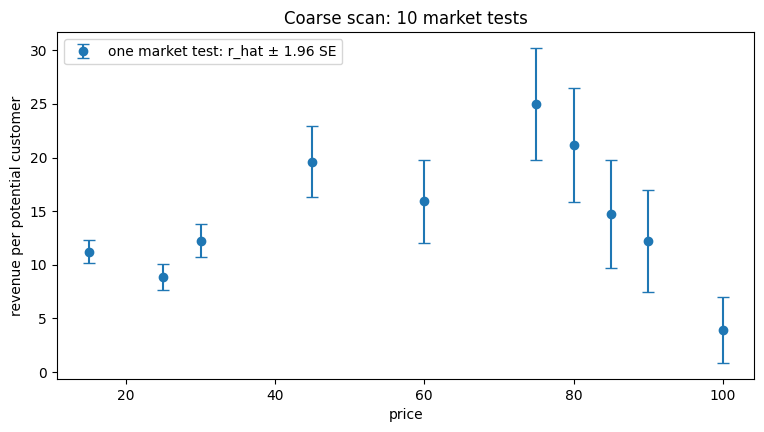

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

grid = np.linspace(0, 100, 1001)
plt.figure(figsize=(9, 4.5))
plt.errorbar(scan_prices, r_hats, yerr=1.96 * ses, fmt="o", capsize=4, label="one market test: r_hat ± 1.96 SE")
plt.xlabel("price")
plt.ylabel("revenue per potential customer")
plt.legend()
plt.title(f"Coarse scan: {tests_run(data)} market tests")
plt.show()

Looks like around 45 and around 75 warrant more testing. 8 tests used out of the 25 test budget so far. Taking advantage of the results obtained from 25 and 30 earlier.

In [9]:
def compare_neighbors(market, price, h, data):
    """Test price - h and price + h once more each (pooled with earlier tests),
    and return the 95% CI for r(price + h) - r(price - h)."""
    lo_p, hi_p = price - h, price + h
    low, high = run_test(market, lo_p, data), run_test(market, hi_p, data)
    d = hi_p * high.mean() - lo_p * low.mean()
    se = np.sqrt(se_formula(low, lo_p) ** 2 + se_formula(high, hi_p) ** 2)
    ci = (d - 1.96 * se, d + 1.96 * se)
    move = "raise" if ci[0] > 0 else ("lower" if ci[1] < 0 else "can't tell")
    return {"price": price, "compared": f"${lo_p:g} vs ${hi_p:g}", "difference": d,
            "ci_low": ci[0], "ci_high": ci[1], "slope": d / (2 * h), "move": move}

comparisons = pd.DataFrame([compare_neighbors(demand, P, 5.0, data) for P in [45, 75, 90]])
print(f"market tests so far: {tests_run(data)}")
comparisons.round(2)

market tests so far: 14


,price,compared,difference,ci_low,ci_high,slope,move
0,45,$40 vs $50,-1.79,-6.07,2.50,-0.18,can't tell
1,75,$70 vs $80,2.60,-4.15,9.35,0.26,can't tell
2,90,$85 vs $95,-6.19,-12.32,-0.06,-0.62,lower


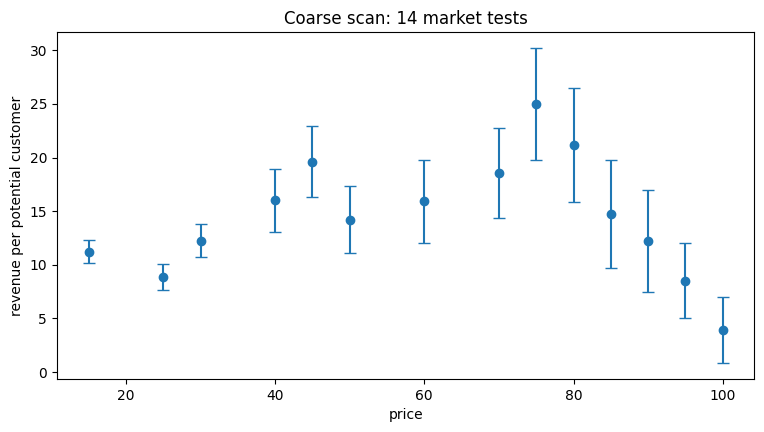

In [10]:
# had wierd errors trying to use data directly, so do this instead.
prices = np.array(list(data.keys()))

ses = np.array([se_formula(np.array(data[P]).flatten(), P) for P in prices])
r_hats = np.array([P * np.array(data[P]).flatten().mean() for P in prices])

plt.figure(figsize=(9, 4.5))
plt.errorbar(prices, r_hats, yerr=1.96 * ses, fmt="o", capsize=4)
plt.xlabel("price")
plt.ylabel("revenue per potential customer")
plt.title(f"Coarse scan: {tests_run(data)} market tests")
plt.show()

Looking at the chart, global peak appears around $75. THis is the best candidate.

In [60]:
# from chart
best_price = 75
max_R = r_hats[3]
se = ses[3]
ci_95_lower = max_R - 1.96*se
ci_95_upper = max_R + 1.96*se
print(f'best revenue: {max_R}')
print(f'95% ci lower at price = 75: {ci_95_lower:.2f}')
print(f'95% ci upper at price = 75: {ci_95_upper:.2f}')

best revenue: 25.0
95% ci lower at price = 75: 19.79
95% ci upper at price = 75: 30.21
